# DIGITAL SIGNAL PROCESSING

## WEEK 3 — LAB 1B

### Convolution, Correlation and Difference Equations

Name: SHAFIYUI SWALEHE IBRAHIMU

Registration Number: 240242491389


Module Code: COU 07506

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Libraries imported successfully!")

Libraries imported successfully!


## Pre-lab Questions

### Question (a)

Convolve x(n) = {1, -1, 2} with h(n) = {2, 1, 0, 1} by hand.

**Solution:**

Output length = L + M - 1

N = 3 + 4 - 1 = 6

y(0) = 1(2) = 2

y(1) = 1(1) + (-1)(2) = -1

y(2) = 1(0) + (-1)(1) + 2(2) = 3

y(3) = 1(1) + (-1)(0) + 2(1) = 3

y(4) = (-1)(1) + 2(0) = -1

y(5) = 2(1) = 2

Therefore:

y(n) = {2, -1, 3, 3, -1, 2}

### Question (b)

Is y(n) = n x(n) time-invariant? Show your test.

**Solution:**

Original system:

y(n) = n x(n)

Delayed input:

T[x(n-k)] = n x(n-k)

Delayed output:

y(n-k) = (n-k)x(n-k)

The two expressions are not equal in general.

Therefore, the system is time-varying because
its output explicitly depends on the time index n.

## Task 3.1 — Convolution from the Definition

This experiment implements linear convolution
using nested loops and verifies the results
using NumPy's convolution function.

In [25]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n-k < len(h):
                y[n] += x[k] * h[n-k]

    return y

x = [1, 2, 3, 1]
h = [1, 1, 1]

print("Manual convolution:", conv(x, h))
print("NumPy convolution:", np.convolve(x, h))

x = [1, -1, 2]
h = [2, 1, 0, 1]

print("\nPre-lab verification:")
print("Manual:", conv(x, h))
print("NumPy:", np.convolve(x, h))

Manual convolution: [1. 3. 6. 6. 4. 1.]
NumPy convolution: [1 3 6 6 4 1]

Pre-lab verification:
Manual: [ 2. -1.  3.  3. -1.  2.]
NumPy: [ 2 -1  3  3 -1  2]


In [26]:
import time

x = np.random.randn(2000)
h = np.random.randn(2000)

start = time.perf_counter()
y1 = conv(x, h)
manual_time = time.perf_counter() - start

start = time.perf_counter()
y2 = np.convolve(x, h)
numpy_time = time.perf_counter() - start

print("Manual time:", manual_time, "seconds")
print("NumPy time:", numpy_time, "seconds")
print("Results match:", np.allclose(y1, y2))

Manual time: 4.56867356500004 seconds
NumPy time: 0.0011633370000936338 seconds
Results match: True


### Observation

The manual convolution and NumPy convolution
produce identical results. NumPy is faster
because it uses optimized numerical operations.
The output length is equal to L + M - 1.

## Task 3.2 — Smoothing a Noisy Signal by Convolution

This experiment investigates noise reduction using
moving-average filters of lengths M = 3, 9 and 25.

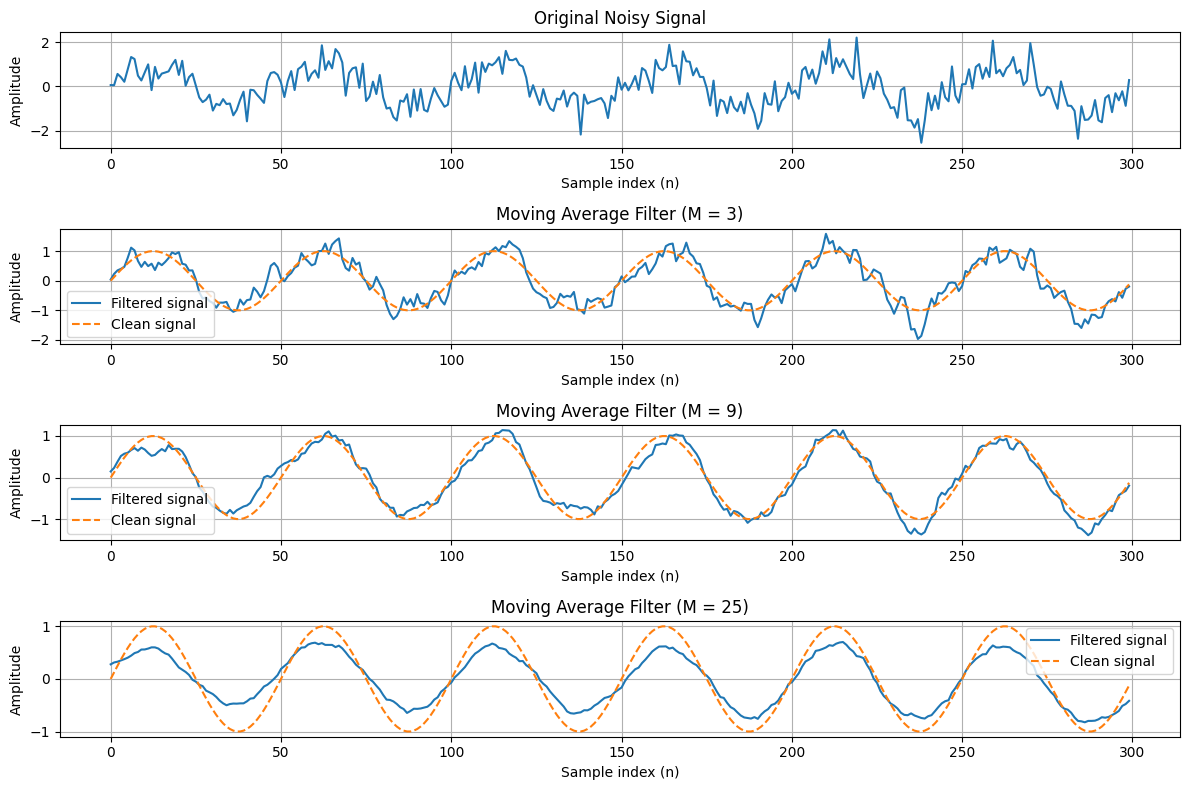

In [27]:
n = np.arange(300)

rng = np.random.default_rng(0)

clean = np.sin(2*np.pi*n/50)
x = clean + 0.5*rng.standard_normal(300)

plt.figure(figsize=(12, 8))

plt.subplot(4, 1, 1)
plt.plot(n, x)
plt.title("Original Noisy Signal")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.grid(True)

for i, M in enumerate([3, 9, 25], start=2):

    h = np.ones(M)/M
    y = np.convolve(x, h, mode="same")

    plt.subplot(4, 1, i)
    plt.plot(n, y, label="Filtered signal")
    plt.plot(n, clean, "--", label="Clean signal")
    plt.title(f"Moving Average Filter (M = {M})")
    plt.xlabel("Sample index (n)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)

plt.tight_layout()
plt.show()

### Observation

- M = 3: Reduces a small amount of noise while
  preserving the original signal shape.

- M = 9: Provides better noise reduction with
  relatively low signal distortion.

- M = 25: Provides stronger noise reduction but
  reduces the amplitude of the original signal.

Increasing the filter length improves noise reduction
but may introduce signal distortion.

## Task 3.3 — Testing Linearity and Time-Invariance Numerically

This experiment tests the linearity and time-invariance
of three discrete-time systems using numerical methods.

In [28]:
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

a, b = 2.0, -3.0

systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x))*x,
    "Moving Average": lambda x: np.convolve(
        x, np.ones(3)/3)[:len(x)]
}

for name, T in systems.items():

    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    xd = np.concatenate([np.zeros(5), x1])[:50]
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
Moving Average  linear=True time-invariant=True


### Observation

1. The squared system is nonlinear because it does
   not satisfy the superposition principle. However,
   it is time-invariant.

2. The system y(n) = n x(n) is linear but time-varying
   because its output explicitly depends on time.

3. The moving-average system satisfies both linearity
   and time-invariance. Therefore, it is an LTI system.

## Task 3.4 — Finding a Hidden Delay with Cross-Correlation

This experiment uses cross-correlation to estimate
the delay between transmitted and received signals
under different noise levels.

Noise level: 0.5
Estimated delay: 37 samples
Estimated distance: 12.691 m
Correct estimate: True


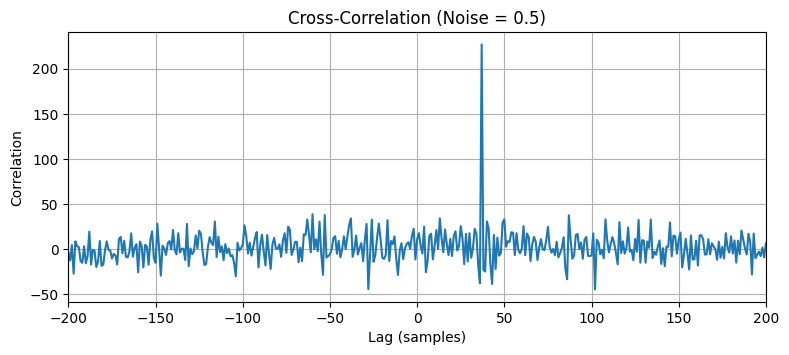

Noise level: 1
Estimated delay: 37 samples
Estimated distance: 12.691 m
Correct estimate: True


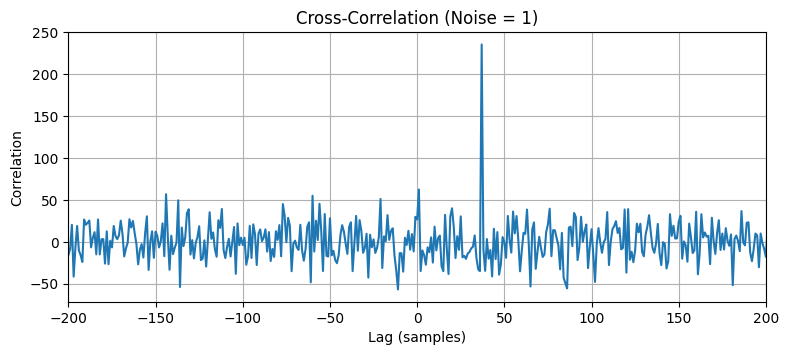

Noise level: 2
Estimated delay: 37 samples
Estimated distance: 12.691 m
Correct estimate: True


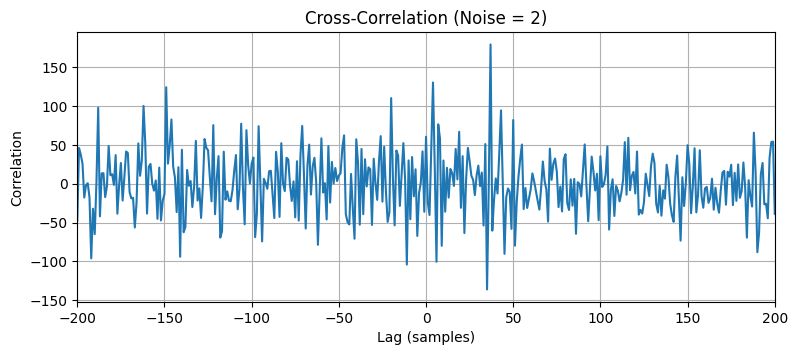

Noise level: 4
Estimated delay: 37 samples
Estimated distance: 12.691 m
Correct estimate: True


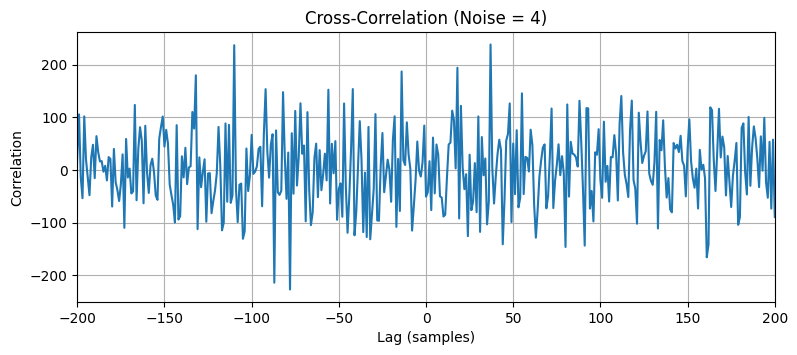

In [29]:
rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)
true_delay = 37

for noise in [0.5, 1, 2, 4]:

    y = np.concatenate([
        np.zeros(true_delay), 0.6*x
    ])[:500] + noise*rng.standard_normal(500)

    r = signal.correlate(y, x, mode="full")

    lags = signal.correlation_lags(
        len(y), len(x), mode="full"
    )

    delay = lags[np.argmax(r)]
    distance = 343 * delay / fs

    print("Noise level:", noise)
    print("Estimated delay:", delay, "samples")
    print("Estimated distance:", distance, "m")
    print("Correct estimate:", delay == true_delay)

    plt.figure()
    plt.plot(lags, r)
    plt.xlim(-200, 200)
    plt.title(f"Cross-Correlation (Noise = {noise})")
    plt.xlabel("Lag (samples)")
    plt.ylabel("Correlation")
    plt.grid(True)
    plt.show()

### Observation

Cross-correlation estimates the delay between
the transmitted and received signals.

Increasing the noise level makes the correlation
peak less reliable and may cause incorrect
delay estimation.

The true delay is 37 samples, corresponding
to a time delay of 0.037 seconds.

Distance = 343 × 0.037

Distance = 12.691 m.

## Task 3.5 — Difference Equation

Given the following difference equation:

$$
y(n)-\frac{3}{4}y(n-1)+\frac{1}{8}y(n-2)
=x(n)+x(n-1)
$$

Rearranging the equation:

$$
y(n)=x(n)+x(n-1)+\frac{3}{4}y(n-1)
-\frac{1}{8}y(n-2)
$$

The closed-form impulse response is:

$$
h(n)=6(0.5)^n-5(0.25)^n
$$

This experiment compares direct recursion, SciPy
lfilter and the closed-form solution. The step
response is also computed to verify the theoretical
steady-state value.

Direct recursion: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
lfilter: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Closed form: [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
All results match: True


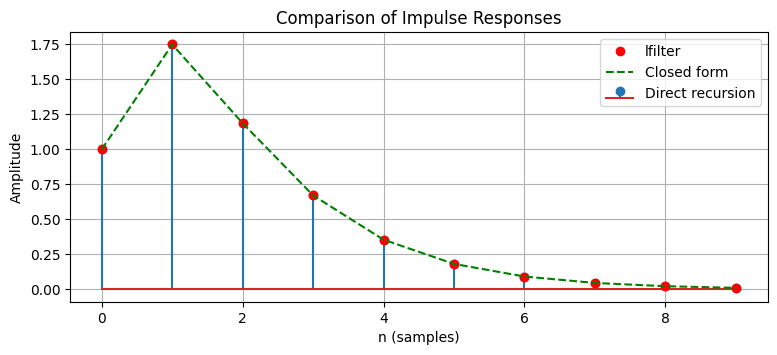

Final value: 5.333333333333323
Theoretical value: 5.333333333333333


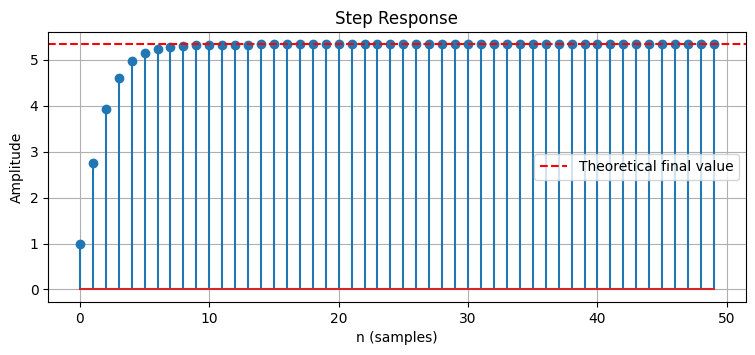

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

n = np.arange(10)

impulse = np.zeros(10)
impulse[0] = 1

b = [1, 1]
a = [1, -0.75, 0.125]

# Method 1: Direct recursion
h1 = np.zeros(10)

for i in range(10):
    h1[i] = impulse[i]

    if i >= 1:
        h1[i] += impulse[i-1] + 0.75*h1[i-1]

    if i >= 2:
        h1[i] -= 0.125*h1[i-2]

# Method 2: lfilter
h2 = signal.lfilter(b, a, impulse)

# Method 3: Closed-form solution
h3 = 6*(0.5**n) - 5*(0.25**n)

print("Direct recursion:", h1)
print("lfilter:", h2)
print("Closed form:", h3)

print("All results match:",
      np.allclose(h1, h2) and np.allclose(h2, h3))

plt.figure()
plt.stem(n, h1, label="Direct recursion")
plt.plot(n, h2, "ro", label="lfilter")
plt.plot(n, h3, "g--", label="Closed form")
plt.title("Comparison of Impulse Responses")
plt.xlabel("n (samples)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

# Step response
n_step = np.arange(50)
step = np.ones(50)
y = signal.lfilter(b, a, step)

H1 = sum(b)/sum(a)

print("Final value:", y[-1])
print("Theoretical value:", H1)

plt.figure()
plt.stem(n_step, y)
plt.axhline(H1, color="red", linestyle="--",
            label="Theoretical final value")
plt.title("Step Response")
plt.xlabel("n (samples)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

## Analysis Questions

### Question 1
Why is np.convolve so much faster than the double loop?
What is the number of multiplications for lengths L and M?

**Answer:**

NumPy convolution is faster because it uses optimized
compiled numerical operations instead of Python loops.

The number of multiplications required is:

$$
N = L \times M
$$

For two signals of length 2000:

$$
N = 2000 \times 2000 = 4,000,000
$$

### Question 2
Which of the three systems in Task 3.3 are LTI?
Could you have predicted this without running code?

**Answer:**

- Squaring system: Nonlinear and time-invariant.
- Multiplication by n: Linear and time-variant.
- Moving-average system: Linear and time-invariant.

Only the moving-average system is LTI.

These results can be predicted mathematically using
the definitions of linearity and time-invariance.

### Question 3
Give two engineering applications of cross-correlation
in Tanzania.

**Answer:**

1. Water leakage detection: Cross-correlation can be
used to estimate the location of leaks in water pipes
by measuring the time delay between acoustic sensors.

2. Radar systems at airports: Cross-correlation can
be used to detect aircraft and estimate their distance
by comparing transmitted and received signals.

### Question 4
Is the system in Task 3.5 FIR or IIR?
Is it stable? Justify from the impulse response.

**Answer:**

The system is an Infinite Impulse Response (IIR)
system because its impulse response continues
indefinitely.

The impulse response is:

$$
h(n)=6(0.5)^n-5(0.25)^n
$$

The system is stable because its impulse response
decays exponentially and is absolutely summable.

Both poles, 0.5 and 0.25, lie inside the unit circle.

## AI-use Statement

ChatGPT was used to assist in understanding DSP
concepts, developing Python code, debugging errors
and explaining experimental results.